# 02 · Preisverteilung und Robustheit gegenüber Extremwerten

## Teilfrage 2

> **Wie ist der Preis pro Nacht verteilt, welche Lage- und Streuungsmasse beschreiben ihn angemessen, und wie stark verändern plausible Extremwerte diese Kennzahlen?**

**Warum dieser Schritt vor den Gruppenvergleichen?** VL02 verlangt «Erst die Form, dann die Kennzahl» (S. 51, 53). Erst wenn wir die Form der Verteilung kennen, wissen wir:

- ob Mittelwert oder Median den typischen Preis beschreibt,
- ob die Standardabweichung als Streuungsmass taugt,
- welche Darstellung (lineare oder logarithmische Achse) die Gruppen in NB03 lesbar macht,
- ob die extremen Preise Fehler sind, die man entfernen müsste, oder ein Teil der Verteilung.

**Datenbasis.** Der Kern-Analysedatensatz aus NB01: Inserate mit Preis und mit einer Abfrage über weniger als 28 Nächte. Er wird hier über dieselbe Funktion neu aus der Rohdatei erzeugt.

**Vorlesungsbezug:** VL02 S. 7–21 (Lage), S. 26–43 (Streuung, Berichtssprache), S. 47–50 (Form, Heavy Tails); VL03 S. 5–9 (Histogramm, Binregeln, KDE), S. 18 (linear oder log), S. 29–34 (ECDF, QQ, kombinierte Diagnostik). TA-Vorlagen: NB02 §1–§3, NB03 §1, §2.3, §3.2–3.4, NB03_Ausreisserregeln.

**Aufbau**

1. Kennzahlen: Lage und Streuung
2. Form I: ECDF und Quantile
3. Form II: Histogramm und KDE, linear und logarithmisch
4. Form III: QQ-Plots
5. Extremwerte: Markierungsregeln je Zimmerart
6. Fallnotizen zu den auffälligsten Preisen
7. Sensitivität: Was ändert sich ohne die Extremwerte?
8. Antwort auf Teilfrage 2

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Projektwurzel finden (Ordner mit src/), damit relative Pfade unabhängig vom Startordner gelten
PROJEKT = Path.cwd().resolve()
while not (PROJEKT / "src").is_dir():
    PROJEKT = PROJEKT.parent
sys.path.insert(0, str(PROJEKT))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
from scipy import stats

from src import daten as D
from src import grafik as G

G.stil()
SEED = D.SEED
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", "'"))

print("Python    ", sys.version.split()[0])
for modul in (np, pd, scipy, matplotlib, sns):
    print(f"{modul.__name__:10s}", modul.__version__)
print("Seed      ", SEED)
print("Snapshot  ", D.SNAPSHOT)

alle, kern, bereinigung = D.bereite_auf()
preis = kern["preis_eur"]
print(f"\nKern-Analysedatensatz: n = {len(kern):,}".replace(",", "'"), f"Inserate; fehlende Preise: {preis.isna().sum()}")

Python     3.14.2
numpy      2.5.4
pandas     3.1.1
scipy      1.18.1
matplotlib 3.11.2
seaborn    0.13.2
Seed       42
Snapshot   2026-09-16



Kern-Analysedatensatz: n = 37'584 Inserate; fehlende Preise: 0


---
## 1. Kennzahlen: Lage und Streuung

Wir berechnen klassische und robuste Kennzahlen nebeneinander, wie in VL02 S. 35 («Bericht: beides, Entscheidung begründen»). Die Standardabweichung rechnen wir mit `ddof=1`. Die Daten sind zwar fast eine Vollerhebung der gefundenen Inserate, `ddof=1` ist aber der Standard in pandas, und bei n = 37 584 ist der Unterschied zu `ddof=0` vernachlässigbar (VL02 S. 28, 38).

In [2]:
k = D.kennzahlen(preis)
D.speichere_tabelle(k.to_frame("Preis pro Nacht (EUR)"), "02_kennzahlen_kern")
k.to_frame("Preis pro Nacht (EUR)")

,Preis pro Nacht (EUR)
n,37'584.00
Mittelwert,367.32
Median,240.43
getrimmtes Mittel 10%,274.85
SD (ddof=1),913.01
Q1,161.67
Q3,385.56
IQR,223.89
MAD,96.18
MAD skaliert (1.4826),142.59


In [3]:
# Heikle Stellen selbst nachrechnen (statt der Funktion blind zu vertrauen)
sortiert = np.sort(preis.to_numpy())
n = len(sortiert)
median_hand = (sortiert[n // 2 - 1] + sortiert[n // 2]) / 2 if n % 2 == 0 else sortiert[n // 2]
mad_hand = np.median(np.abs(sortiert - median_hand))
assert np.isclose(median_hand, k["Median"]) and np.isclose(mad_hand, k["MAD"])
print(f"Median von Hand: {median_hand:.2f} EUR, MAD von Hand: {mad_hand:.2f} EUR (stimmen mit der Tabelle überein)")

unter_mittelwert = (preis < preis.mean()).mean()
print(f"Anteil der Inserate unter dem Mittelwert: {unter_mittelwert:.1%}")
print(f"Maximum / Median: {preis.max() / preis.median():,.0f}".replace(",", "'"))
print(f"SD / Mittelwert (Variationskoeffizient): {k['SD (ddof=1)'] / k['Mittelwert']:.2f}")

Median von Hand: 240.43 EUR, MAD von Hand: 96.18 EUR (stimmen mit der Tabelle überein)
Anteil der Inserate unter dem Mittelwert: 72.9%
Maximum / Median: 419
SD / Mittelwert (Variationskoeffizient): 2.49


**Beobachtung**

- Der Mittelwert (367 €) liegt um gut 50 % über dem Median (240 €). 73 % der Inserate kosten weniger als der Mittelwert.
- Die Standardabweichung (913 €) ist **grösser als der Mittelwert**.
- IQR (224 €) und MAD (96 €; skaliert 143 €) sind dagegen von der Grössenordnung der typischen Preise.

**Interpretation**

- Die Verteilung ist stark **rechtsschief** (VL02 S. 21, 48). Der Mittelwert beschreibt kein typisches Inserat. Er wäre nur dann die richtige Zahl, wenn eine **Summe** gefragt wäre, etwa ein Gesamtumsatz (NB02 §1.1). Diese Frage stellen wir nicht.
- Die SD wird von wenigen sehr grossen Werten getrieben. Ein SD-Bericht hätte hier keine anschauliche Bedeutung.
- Wir berichten deshalb **Median, Quartile (IQR) und P90**. Mittelwert und SD stehen nur als Gegenprobe da.

Ob die Abweichung von einzelnen Fehlwerten oder von einer langen Flanke kommt, zeigen erst die Grafiken (VL02 S. 50).

---
## 2. Form I: ECDF und Quantile

Wir beginnen mit der ECDF, wie es die Diagnose-Routine vorgibt (VL03 S. 34; NB03 §3.4). Sie braucht keine Bins und keine Bandbreite und zeigt jedes Quantil direkt.

Die x-Achse ist **logarithmisch**: Die Preise reichen von 10 € bis 100 000 €. Wichtig ist der Unterschied zur Datentransformation. Eine Log-**Achse** ändert nur die Abstände auf dem Papier. Die Werte und alle Kennzahlen bleiben in Euro (NB03 §2.3). Nullen gibt es keine (NB01 §6), deshalb geht kein Wert verloren.

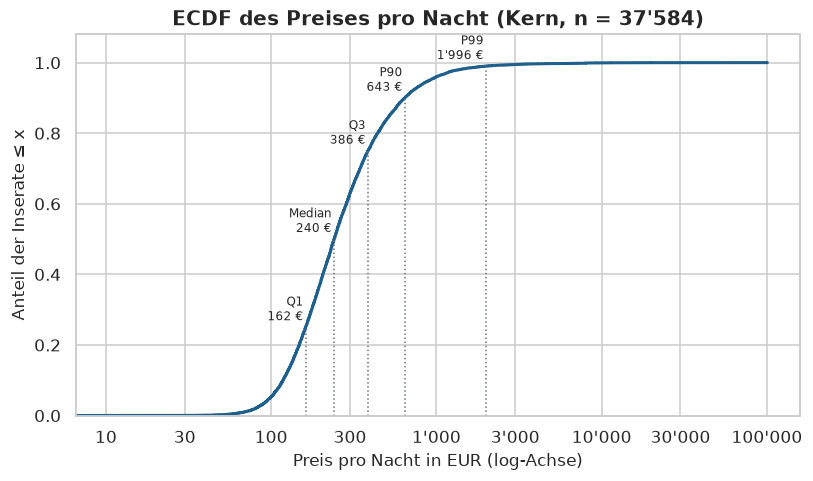

P1         69.00
P5         98.90
P10       118.00
P25       161.70
P50       240.40
P75       385.60
P90       643.20
P95       912.80
P99     1'996.20
P99.9   8'406.40


In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.ecdfplot(x=preis, ax=ax, color=G.FARBEN_ZIMMERART["Entire home/apt"], linewidth=2)
for q, label in [(0.25, "Q1"), (0.5, "Median"), (0.75, "Q3"), (0.9, "P90"), (0.99, "P99")]:
    wert = preis.quantile(q)
    ax.plot([wert, wert], [0, q], color=G.GRAU, linestyle=":", linewidth=1)
    ax.text(wert * 0.97, q + 0.02, f"{label}\n{G.zahl(wert)} €", ha="right", fontsize=8)
G.log_preisachse(ax)
ax.set(ylabel="Anteil der Inserate ≤ x", title=f"ECDF des Preises pro Nacht (Kern, n = {G.zahl(len(preis))})", ylim=(0, 1.08))
G.speichere(fig, "02_ecdf_preis")
plt.show()
quantile = preis.quantile([0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]).round(1)
quantile.index = [f"P{100 * q:g}" for q in quantile.index]
print(quantile.to_string())

**Lesehilfe.** Der Preis auf der x-Achse ist abgetragen gegen den Anteil der Inserate, die höchstens so viel kosten.

**Beobachtung**

- Die mittleren 50 % der Inserate kosten zwischen 162 € und 386 € pro Nacht.
- 90 % kosten höchstens 643 €.
- Die Kurve ist zwischen etwa 100 € und 600 € steil, danach steigt sie über zwei Grössenordnungen langsam gegen 1. Oberhalb von 2 000 € liegt nur noch 1 % der Inserate.

**Interpretation.** Die Kurve flacht oben **allmählich** ab und zeigt keinen Sprung oder Absatz. Das spricht für eine lange, durchgehende rechte Flanke (Heavy Tail), nicht für eine kleine Gruppe isolierter Fehlwerte (VL02 S. 50). Ganz am Rand ist die Kurve aber so dünn besetzt, dass einzelne Werte dort Fehler sein können. Das prüfen wir in Abschnitt 6.

---
## 3. Form II: Histogramm und KDE, linear und logarithmisch

**Wahl der Parameter (VL03 S. 6, 9, 12):**

- **Bins** nach Freedman-Diaconis (FD), dem robusten Standard bei Schiefe. Wir berechnen die Klassenzahl selbst, um zu zeigen, dass die Regel auf der linearen Skala nicht brauchbar ist.
- **Lineare Darstellung** nur bis P99. Das Abschneiden steht in der Achsenbeschriftung, zusammen mit der Zahl der Werte darüber.
- **KDE auf log₁₀(Preis)** mit `bw_adjust` 0.5, 1 und 2. Hier ist der Logarithmus eine **Transformation**: Die KDE schätzt die Dichte der neuen Variable log₁₀(Preis).

In [5]:
def fd_klassen(x):
    q1, q3 = np.percentile(x, [25, 75])
    breite = 2 * (q3 - q1) / len(x) ** (1 / 3)
    return breite, int(np.ceil((x.max() - x.min()) / breite))

log_preis = np.log10(preis)
breite_lin, k_lin = fd_klassen(preis.to_numpy())
breite_log, k_log = fd_klassen(log_preis.to_numpy())
print(f"FD linear: Klassenbreite {breite_lin:.1f} EUR -> {k_lin:,} Klassen bis zum Maximum".replace(",", "'"))
print(f"FD log10:  Klassenbreite {breite_log:.3f} log-Einheiten -> {k_log} Klassen")
print(f"Zum Vergleich: Sturges {int(np.ceil(np.log2(len(preis)) + 1))}, Wurzelregel {int(np.ceil(np.sqrt(len(preis))))}")
p99 = preis.quantile(0.99)
print(f"P99 = {p99:,.0f} EUR; {int((preis > p99).sum())} Werte liegen darüber".replace(",", "'"))
print(f"Schiefe: Rohpreis {stats.skew(preis):.1f}, log10(Preis) {stats.skew(log_preis):.2f}")

FD linear: Klassenbreite 13.4 EUR -> 7'530 Klassen bis zum Maximum
FD log10:  Klassenbreite 0.023 log-Einheiten -> 177 Klassen
Zum Vergleich: Sturges 17, Wurzelregel 194
P99 = 1'996 EUR; 376 Werte liegen darüber
Schiefe: Rohpreis 56.0, log10(Preis) 0.89


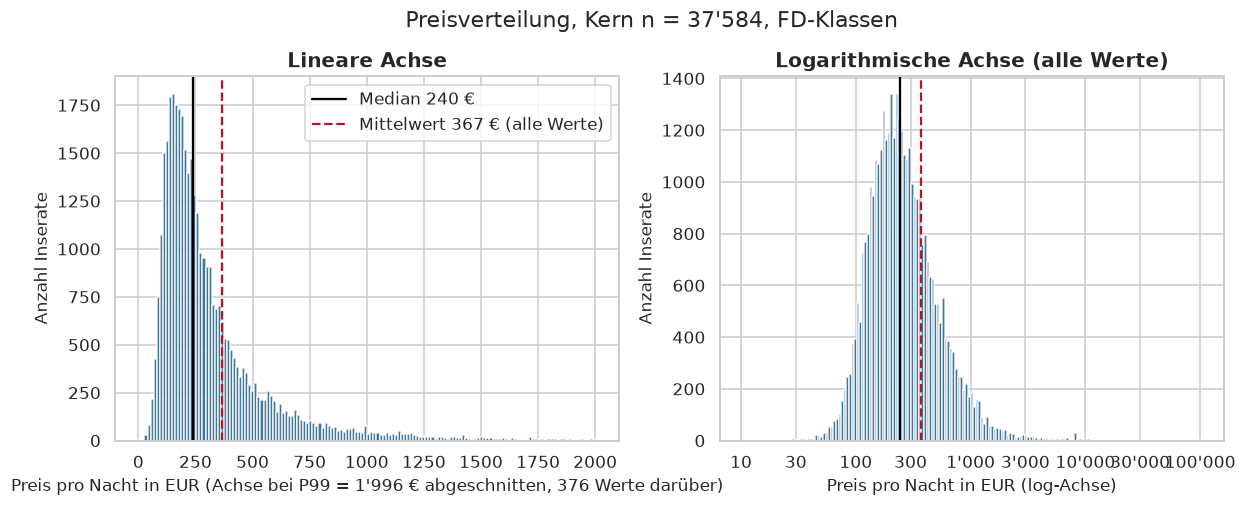

In [6]:
fig, achsen = plt.subplots(1, 2, figsize=(13, 4.3))

# Links: linear, mit FD-Klassenbreite, bis P99
bins_lin = np.arange(0, p99 + breite_lin, breite_lin)
achsen[0].hist(preis[preis <= p99], bins=bins_lin, color=G.FARBEN_ZIMMERART["Entire home/apt"], alpha=0.85)
achsen[0].axvline(preis.median(), color="black", linewidth=1.5, label=f"Median {preis.median():.0f} €")
achsen[0].axvline(preis.mean(), color=G.AKZENT, linewidth=1.5, linestyle="--", label=f"Mittelwert {preis.mean():.0f} € (alle Werte)")
achsen[0].set(title="Lineare Achse",
              xlabel=f"Preis pro Nacht in EUR (Achse bei P99 = {G.zahl(p99)} € abgeschnitten, {int((preis > p99).sum())} Werte darüber)",
              ylabel="Anzahl Inserate")
achsen[0].legend()

# Rechts: dieselben Werte auf log-Achse, Bins gleich breit in log-Einheiten (FD auf log10)
bins_log = 10 ** np.arange(log_preis.min(), log_preis.max() + breite_log, breite_log)
achsen[1].hist(preis, bins=bins_log, color=G.FARBEN_ZIMMERART["Entire home/apt"], alpha=0.85)
achsen[1].axvline(preis.median(), color="black", linewidth=1.5)
achsen[1].axvline(preis.mean(), color=G.AKZENT, linewidth=1.5, linestyle="--")
G.log_preisachse(achsen[1])
achsen[1].set(title="Logarithmische Achse (alle Werte)", ylabel="Anzahl Inserate")

fig.suptitle(f"Preisverteilung, Kern n = {G.zahl(len(preis))}, FD-Klassen", y=1.02)
G.speichere(fig, "02_histogramm_linear_log")
plt.show()

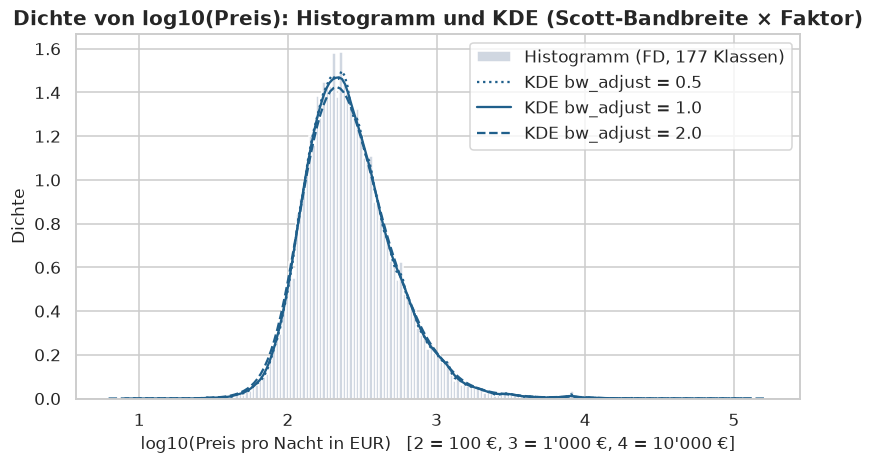

In [7]:
# KDE auf der transformierten Variable log10(Preis): Bandbreite variieren (NB03 §1.4)
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.hist(log_preis, bins=k_log, density=True, color="#d0d7e1", label=f"Histogramm (FD, {k_log} Klassen)")
for faktor, stil in [(0.5, ":"), (1.0, "-"), (2.0, "--")]:
    sns.kdeplot(x=log_preis, bw_adjust=faktor, ax=ax, linestyle=stil, color=G.FARBEN_ZIMMERART["Entire home/apt"],
                label=f"KDE bw_adjust = {faktor}")
ax.set(xlabel="log10(Preis pro Nacht in EUR)   [2 = 100 €, 3 = 1'000 €, 4 = 10'000 €]",
       ylabel="Dichte", title="Dichte von log10(Preis): Histogramm und KDE (Scott-Bandbreite × Faktor)")
ax.legend()
G.speichere(fig, "02_kde_log_bandbreiten")
plt.show()

**Beobachtung**

- Auf der linearen Achse drängt sich fast alles links zusammen, obwohl die Achse schon bei P99 endet.
- Die FD-Regel würde auf der linearen Skala über 7 500 Klassen verlangen. Das liegt nicht an der Masse der Daten, sondern daran, dass die Spannweite bis 100 666 € reicht.
- Auf der logarithmischen Achse wird die Form lesbar: **ein Gipfel** um 200 €, ein steilerer Anstieg links und eine längere rechte Flanke.
- Die KDE von log₁₀(Preis) zeigt bei allen drei Bandbreiten denselben einen Gipfel. Bei `bw_adjust = 0.5` erscheinen kleine Zacken, die bei 1 und 2 verschwinden. Wir werten sie als Rauschen bzw. als Effekt runder Preise.
- Die Schiefe sinkt von 56 (Rohpreis) auf 0.89 (log₁₀). Rechtsschief bleibt die Verteilung trotzdem.

**Interpretation**

- Die Verteilung ist **unimodal und stark rechtsschief**, mit einer Flanke über mehrere Grössenordnungen.
- Für Gruppenvergleiche verwenden wir deshalb die **log-Achse**, berichten aber Kennzahlen in Euro.
- Wichtig: Dass log₁₀(Preis) symmetrischer aussieht, **beweist keine Log-Normalverteilung**. Das prüft der QQ-Plot.

---
## 4. Form III: QQ-Plots

Wir vergleichen die Quantile der Daten mit den Quantilen einer Normalverteilung (VL03 S. 32–33):

- Ein **Bogen** (beide Enden über der Linie) zeigt Rechtsschiefe.
- Eine **S-Kurve** zeigt schwere Ränder auf beiden Seiten.

Gezeichnet werden zwei QQ-Plots: für den Rohpreis und für log₁₀(Preis).

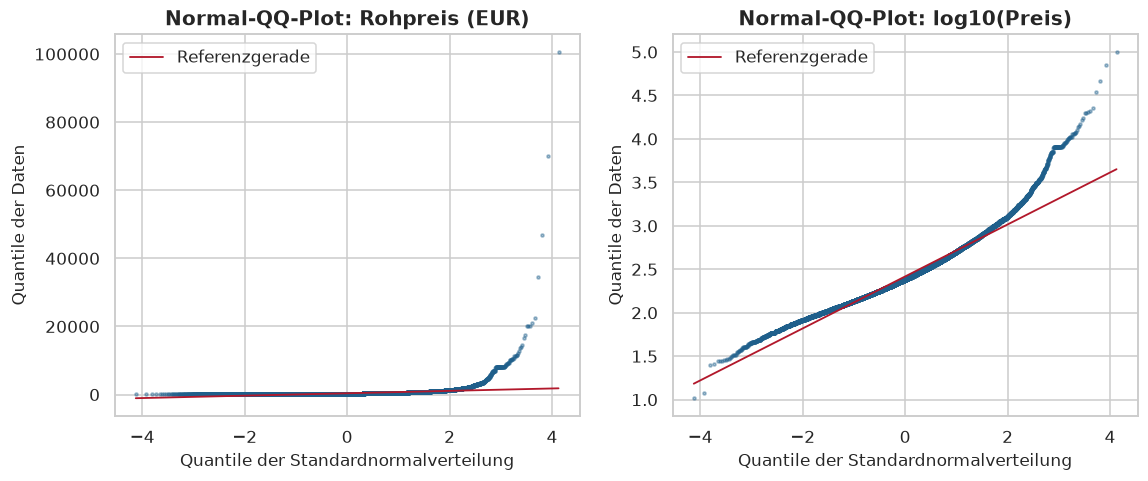

In [8]:
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, werte, titel in [(achsen[0], preis, "Rohpreis (EUR)"), (achsen[1], log_preis, "log10(Preis)")]:
    (theo, beob), (steigung, achsenabschnitt, _) = stats.probplot(werte, dist="norm")
    ax.scatter(theo, beob, s=4, alpha=0.4, color=G.FARBEN_ZIMMERART["Entire home/apt"])
    ax.plot(theo, steigung * theo + achsenabschnitt, color=G.AKZENT, linewidth=1.2, label="Referenzgerade")
    ax.set(title=f"Normal-QQ-Plot: {titel}", xlabel="Quantile der Standardnormalverteilung", ylabel="Quantile der Daten")
    ax.legend(loc="upper left")
G.speichere(fig, "02_qq_roh_log")
plt.show()

**Beobachtung**

- **Rohpreis:** Die Punkte liegen fast über den ganzen Bereich flach und schiessen am rechten Ende steil nach oben. Das ist ein extremer Bogen.
- **log₁₀(Preis):** In der Mitte folgen die Punkte der Geraden weitgehend. An **beiden** Enden weichen sie ab, rechts deutlich stärker (schwerer rechter Rand).

**Interpretation**

- Der Rohpreis ist sehr deutlich nicht normalverteilt, sondern rechtsschief mit schwerem Tail. Mittelwert und SD sind damit als Hauptkennzahlen ausgeschlossen.
- Auch log₁₀(Preis) ist nur in der Mitte normalnah. Wir behaupten deshalb **keine bestimmte Verteilungsfamilie**.
- Für die Analyse brauchen wir auch keine. Mediane, Quantile und Rangmasse kommen ohne Verteilungsannahme aus.

**Entscheidungssatz fürs Log (Muster NB03 §3.4):**
> Der Preis pro Nacht (Kern, n = 37 584, keine fehlenden Werte) ist unimodal und stark rechtsschief mit schwerem rechtem Tail (QQ-Bogen; Schiefe 56, auf log₁₀ 0.89). Wir berichten Median 240 € mit IQR 162–386 € und P90 643 €. Mittelwert (367 €) und SD (913 €) dienen nur als Gegenprobe. Die Grafiken verwenden eine log-Achse (FD-Bins auf log₁₀, 177 Klassen; KDE-Bandbreite Scott × 1, geprüft mit 0.5 und 2).

---
## 5. Extremwerte: Markierungsregeln je Zimmerart

Markierungsregeln sind **Hinweise**, keine Fehlerdiagnose (NB03_Ausreisserregeln §1). Wir rechnen sie **je Zimmerart**, weil globale Grenzen Gruppen mit unterschiedlicher Lage vermischen. Verwendet werden drei Regeln:

- **Tukey** auf dem Rohpreis: Werte über Q3 + 1.5 · IQR.
- **Modifizierter z-Score** auf dem Rohpreis: |0.6745 · (x − Median) / MAD| > 3.5.
- **Tukey auf log₁₀(Preis)**. Diese Grenze ist an die schiefe Form angepasst.

Dazu kommt unsere **vorab festgelegte inhaltliche Regel** `flag_extrem`: Preis ≥ 10 000 € oder mehr als 1 000 € pro Person und Nacht.

In [9]:
def markierungen(x: pd.Series) -> pd.Series:
    q1, q3 = x.quantile([0.25, 0.75])
    med = x.median()
    mad = (x - med).abs().median()
    assert mad > 0, "MAD = 0: modifizierter z-Score nicht definiert"
    lx = np.log10(x)
    lq1, lq3 = lx.quantile([0.25, 0.75])
    return pd.Series({
        "n": len(x),
        "Tukey-Grenze oben (EUR)": q3 + 1.5 * (q3 - q1),
        "Tukey markiert": int((x > q3 + 1.5 * (q3 - q1)).sum()),
        "mod. z > 3.5 markiert": int((0.6745 * (x - med) / mad).abs().gt(3.5).sum()),
        "Tukey auf log10: Grenze oben (EUR)": 10 ** (lq3 + 1.5 * (lq3 - lq1)),
        "Tukey auf log10 markiert (oben)": int((lx > lq3 + 1.5 * (lq3 - lq1)).sum()),
        "Tukey auf log10 markiert (unten)": int((lx < lq1 - 1.5 * (lq3 - lq1)).sum()),
    })

regeln = kern.groupby("zimmerart", observed=True)["preis_eur"].apply(markierungen).unstack()
regeln["flag_extrem (inhaltliche Regel)"] = kern.groupby("zimmerart", observed=True)["flag_extrem"].sum()
D.speichere_tabelle(regeln, "02_markierungsregeln_je_zimmerart")
regeln

,n,Tukey-Grenze oben (EUR),Tukey markiert,mod. z > 3.5 markiert,Tukey auf log10: Grenze oben (EUR),Tukey auf log10 markiert (oben),Tukey auf log10 markiert (unten),flag_extrem (inhaltliche Regel)
zimmerart,,,,,,,,
Entire home/apt,32'292.00,747.42,2'525.00,2'436.00,1'433.71,593.00,9.00,60
Private room,4'908.00,507.92,390.00,394.00,1'066.20,110.00,0.00,57
Hotel room,266.00,1'017.53,9.00,8.00,2'165.68,0.00,0.00,0
Shared room,118.00,130.92,15.00,15.00,182.87,11.00,0.00,0


**Beobachtung**

- Bei den ganzen Unterkünften markiert Tukey auf dem Rohpreis **2 525 Inserate**, also 8 % (Grenze 747 €). Der modifizierte z-Score markiert ähnlich viele.
- Tukey auf log₁₀ markiert 593 Inserate, erst ab etwa 1 434 €.
- Unsere inhaltliche Regel kennzeichnet 60 ganze Unterkünfte und 57 Privatzimmer.

**Interpretation**

- Die statistischen Regeln markieren grosse Teile der **legitimen rechten Flanke**. Ein Preis von 800 € für eine Wohnung mit vier Zimmern ist nicht verdächtig. Als Löschregel wären Tukey und z-Score hier falsch: Sie würden genau den Teil entfernen, der die Schiefe ausmacht.
- Aussagekräftig ist die Frage, ob ein Wert **zu seinem Inserat passt**, also zu Grösse und Art. Das prüft die inhaltliche Regel über den Preis pro Person.
- Die Regel kennzeichnet auffällig viele **Privatzimmer** (57 von 4 908, also 1.2 %, gegenüber 0.2 % bei ganzen Unterkünften). Ein Privatzimmer für über 1 000 € pro Person und Nacht ist inhaltlich besonders unwahrscheinlich.

---
## 6. Fallnotizen zu den auffälligsten Preisen

Wir gehen die fünf Prüffragen aus NB03_Ausreisserregeln §3 für die höchsten Preise durch. Eine externe Quelle für den «wahren» Preis haben wir nicht. Kein Wert kann deshalb als Fehler **belegt** werden.

In [10]:
merkmale = ["id", "preis_eur", "preis_pro_person", "room_type", "property_type", "accommodates", "bedrooms",
            "abfrage_naechte", "number_of_reviews", "availability_365", "inserate_des_hosts", "name"]
faelle = kern.nlargest(12, "preis_eur")[merkmale].copy()
faelle["name"] = faelle["name"].str.slice(0, 45)
D.speichere_tabelle(faelle, "02_fallnotizen_top12", index=False)
faelle

,id,preis_eur,preis_pro_person,room_type,property_type,accommodates,bedrooms,abfrage_naechte,number_of_reviews,availability_365,inserate_des_hosts,name
44189,1073735761485091887,100'666.10,14'380.87,Entire home/apt,Entire home,7,4.00,21.00,8,177,1,Une belle maison Paris intramuros
52036,1140015032188028758,70'080.00,11'680.00,Entire home/apt,Entire rental unit,6,3.00,1.00,3,274,19,Écrin Luxe Kléber 6 places
29872,608065383770041323,46'789.00,23'394.50,Entire home/apt,Entire rental unit,2,1.00,1.00,6,270,1,Studio 7eme arrondissement
5821,7447891,34'536.67,17'268.33,Entire home/apt,Entire condo,2,1.00,3.00,2,363,1,indisponible
43301,1025116958672853142,22'516.00,2'814.50,Entire home/apt,Entire rental unit,8,4.00,1.00,0,171,4,1.75 Paris La Sève Appartement Deluxe
76597,1760222610865413261,21'000.00,2'625.00,Entire home/apt,Entire rental unit,8,4.00,3.00,0,116,48,Par005 - Luxury Apartment in the Golden Trian
56430,1197728179717957125,20'132.00,2'013.20,Entire home/apt,Entire rental unit,10,5.00,5.00,0,363,48,Par134 - Stunning apartment in St Germain des
67165,1527513149902080396,20'032.50,5'008.12,Entire home/apt,Entire rental unit,4,2.00,2.00,19,15,1,Charmant appartement en plein centre de Paris
43302,1025125588051463694,20'000.00,3'333.33,Entire home/apt,Entire rental unit,6,3.00,1.00,0,171,4,1.75 Paris La Sève Penthouse
52904,1160725601494020996,17'477.20,2'184.65,Entire home/apt,Entire rental unit,8,4.00,5.00,3,365,48,Par096 - Luxury penthouse on Avenue Montaigne


In [11]:
# Was unterscheidet die gekennzeichneten Fälle vom Rest des Kerns?
gekennzeichnet = kern["flag_extrem"].map({True: "flag_extrem", False: "übriger Kern"})
profil = pd.DataFrame({
    "Inserate": kern.groupby(gekennzeichnet).size(),
    "Anteil ohne Review (%)": 100 * kern["number_of_reviews"].eq(0).groupby(gekennzeichnet).mean(),
    "Median verfügbare Tage (365)": kern.groupby(gekennzeichnet)["availability_365"].median(),
    "Anteil Host ≥ 10 Inserate (%)": 100 * kern["inserate_des_hosts"].ge(10).groupby(gekennzeichnet).mean(),
    "Anteil Privatzimmer (%)": 100 * kern["room_type"].eq("Private room").groupby(gekennzeichnet).mean(),
}).T.round(1)
D.speichere_tabelle(profil, "02_profil_gekennzeichnet")
profil

flag_extrem,flag_extrem,übriger Kern
Inserate,117.00,37'467.00
Anteil ohne Review (%),66.70,14.40
Median verfügbare Tage (365),364.00,229.00
Anteil Host ≥ 10 Inserate (%),49.60,19.60
Anteil Privatzimmer (%),48.70,12.90


**Fallnotizen (Auswahl; Prüffragen nach NB03_Ausreisserregeln §3)**

| Fall-ID | Wert | Prüfung | Entscheidung |
|---|---|---|---|
| 7447891 | 34 537 €/Nacht, 2 Gäste | Das Inserat heisst «indisponible» (nicht verfügbar) und ist 363 Tage im Jahr frei. Das ist ein typisches Muster für einen **Sperrpreis**, mit dem ein Host Buchungen verhindert. | Verdacht auf Platzhalter, nicht belegt. **Behalten und gekennzeichnet.** |
| 608065383770041323 | 46 789 €/Nacht, Studio, 2 Gäste | Für ein Studio mit 6 Reviews ist ein Preis im fünfstelligen Bereich nicht plausibel, auch kein Einheitenfehler erkennbar (kein Faktor 100). | Zweifelhaft. **Behalten und gekennzeichnet.** |
| 1073735761485091887 | 100 666 €/Nacht, Haus, 7 Gäste | Abfrage über 21 Nächte; 8 Reviews. Ein Gesamtpreis von über 2 Mio. € für drei Wochen ist nicht plausibel. | Zweifelhaft. **Behalten und gekennzeichnet.** |
| 1760222610865413261 u. a. («Par005», «Par134», «Par096») | 17 000–21 000 €/Nacht, 8–10 Gäste, laut Inseratsname Luxuswohnungen im 8. bzw. 6. Arrondissement | Ein professioneller Anbieter mit 48 Inseraten. Ein Luxussegment mit solchen Preisen ist möglich. | **Plausibles besonderes Angebot**, behalten. Formal fällt es unter die vorab festgelegte Regel (≥ 10 000 €), deshalb gekennzeichnet. |

**Profil der gekennzeichneten Fälle.** Zwei Drittel der 117 gekennzeichneten Inserate haben **kein einziges Review** (übriger Kern: 15 %). Sie sind fast das ganze Jahr verfügbar. Etwa die Hälfte gehört Hosts mit ≥ 10 Inseraten.

**Interpretation (Vermutung).** Ein Teil der Extrempreise sind wohl **keine realen Angebote**, sondern Sperr- oder Platzhalterpreise. Ein anderer Teil ist Luxussegment. Mit den vorhandenen Daten können wir die beiden Gruppen nicht sicher trennen.

**Entscheidung**

- Wir **löschen nichts**.
- Wir berichten **robuste Kennzahlen**.
- Wir prüfen alle zentralen Aussagen zusätzlich **ohne die gekennzeichneten Fälle**.

---
## 7. Sensitivität: Was ändert sich ohne die Extremwerte?

Wir vergleichen drei Varianten. Sie sind in `src/daten.py` definiert und wurden vor der Gruppenauswertung festgelegt:

1. Kern (alle Werte)
2. ohne die 117 gekennzeichneten Fälle
3. Preise je Zimmerart beim 99.5-%-Quantil winsorisiert, also gekappt statt entfernt (VL02 S. 14)

In [12]:
varianten = D.sensitivitaets_varianten(alle, kern)
auswahl = ["Kern (Hauptanalyse)", "ohne Extrem-Kennzeichnung", "winsorisiert 99.5% je Zimmerart"]
sensitivitaet = pd.DataFrame({name: D.kennzahlen(varianten[name]["preis_eur"]) for name in auswahl}).T
spalten = ["n", "Median", "Q1", "Q3", "IQR", "MAD", "P90", "getrimmtes Mittel 10%", "Mittelwert", "SD (ddof=1)", "Maximum"]
sensitivitaet = sensitivitaet[spalten]
aenderung = (100 * (sensitivitaet / sensitivitaet.loc["Kern (Hauptanalyse)"] - 1)).round(1)
D.speichere_tabelle(sensitivitaet, "02_sensitivitaet_extremwerte")
print("Kennzahlen (EUR):")
display(sensitivitaet.round(1))
print("Veränderung gegenüber dem Kern (%):")
display(aenderung)

Kennzahlen (EUR):


,n,Median,Q1,Q3,IQR,MAD,P90,getrimmtes Mittel 10%,Mittelwert,SD (ddof=1),Maximum
Kern (Hauptanalyse),37'584.00,240.40,161.70,385.60,223.90,96.20,643.20,274.90,367.30,913.00,100'666.10
ohne Extrem-Kennzeichnung,37'467.00,240.00,161.50,383.00,221.50,95.70,635.00,273.50,338.60,359.60,9'219.20
winsorisiert 99.5% je Zimmerart,37'584.00,240.40,161.70,385.60,223.90,96.20,643.20,274.90,348.30,419.50,8'000.00


Veränderung gegenüber dem Kern (%):


,n,Median,Q1,Q3,IQR,MAD,P90,getrimmtes Mittel 10%,Mittelwert,SD (ddof=1),Maximum
Kern (Hauptanalyse),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ohne Extrem-Kennzeichnung,-0.30,-0.20,-0.10,-0.70,-1.00,-0.50,-1.30,-0.50,-7.80,-60.60,-90.80
winsorisiert 99.5% je Zimmerart,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-5.20,-54.10,-92.10


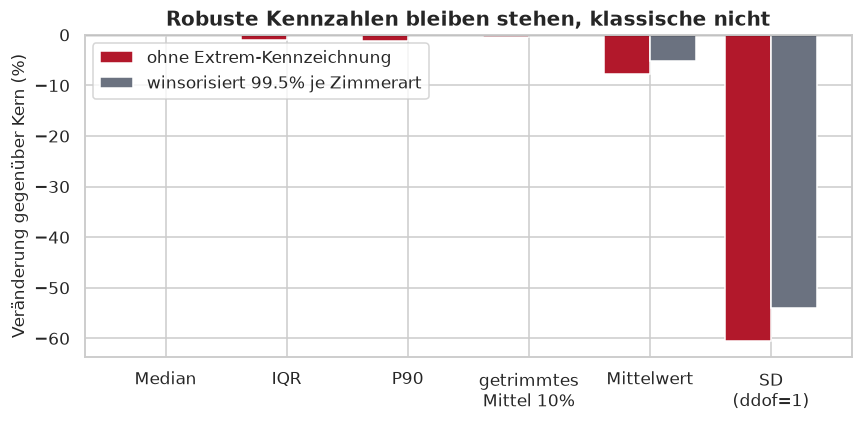

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
kz = ["Median", "IQR", "P90", "getrimmtes Mittel 10%", "Mittelwert", "SD (ddof=1)"]
x = np.arange(len(kz))
for i, (name, farbe) in enumerate(zip(auswahl[1:], [G.AKZENT, G.GRAU])):
    ax.bar(x + (i - 0.5) * 0.38, aenderung.loc[name, kz], width=0.38, color=farbe, label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, [k.replace(" ", "\n", 1) for k in kz])
ax.set(ylabel="Veränderung gegenüber Kern (%)", title="Robuste Kennzahlen bleiben stehen, klassische nicht")
ax.legend()
G.speichere(fig, "02_sensitivitaet_kennzahlen")
plt.show()

**Beobachtung**

- Ohne die 117 gekennzeichneten Fälle (0.3 % der Inserate) ändern sich Median, IQR und P90 um höchstens 1.3 %.
- Der Mittelwert sinkt dagegen um 8 %, die SD um 61 % (von 913 € auf 360 €).
- Die Winsorisierung verändert per Konstruktion keine Quantile. Sie senkt den Mittelwert um 5 % und die SD um 54 %.

**Interpretation.** Die Wahl der Kennzahl ist **wichtiger** als die Frage, was man mit den Extremwerten macht:

- Mit Median und Quantilen hängen unsere Aussagen praktisch nicht davon ab, ob die zweifelhaften Fälle Fehler sind oder nicht.
- Mit Mittelwert und SD würde ein Bruchteil eines Prozents der Inserate das Ergebnis bestimmen.

Das ist das Argument aus VL02 S. 35 in Zahlen.

---
## 8. Antwort auf Teilfrage 2

**Form.** Die Preise pro Nacht (Kern, n = 37 584) sind **unimodal und stark rechtsschief** und haben einen schweren rechten Tail über mehrere Grössenordnungen. ECDF, Histogramm/KDE und QQ-Plot zeigen das übereinstimmend. Auch log₁₀(Preis) ist nur in der Mitte normalnah. Eine Verteilungsfamilie behaupten wir nicht.

**Kennzahlen.**

- Typisch ist ein Preis von **240 € pro Nacht (Median)**. Die mittlere Hälfte der Inserate liegt zwischen **162 € und 386 €**, 90 % kosten höchstens **643 €**.
- Der Mittelwert (367 €) und vor allem die SD (913 €) beschreiben kein typisches Inserat.

**Extremwerte.**

- Die statistischen Regeln markieren Tausende Werte der legitimen Flanke und taugen deshalb nicht als Löschkriterium.
- Die 117 inhaltlich gekennzeichneten Fälle sind zum Teil vermutlich Sperrpreise, zum Teil Luxusangebote. Belegen lässt sich keiner als Fehler.
- Die robusten Kennzahlen ändern sich ohne sie um höchstens 1.3 %.

**Grenzen**

- Alle Zahlen gelten für Abfragepreise der buchbaren Inserate. Sie hängen auch vom Abfragetermin ab (NB04).
- Ob einzelne Extremwerte reale Angebote sind, können wir ohne externe Quelle nicht entscheiden.

**Übergang zu NB03.** Für die Gruppenvergleiche folgt daraus: Wir vergleichen **Mediane, Quartile und Anteile** und zeichnen auf der **log-Achse**. Für Zusammenhänge verwenden wir **Rangmasse**, weil Pearson auf diese Ausreisser so empfindlich reagiert wie der Mittelwert (VL04 S. 22).